In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("./credit_risk_loan_portfolio_synthetic.csv")
df.head()

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category
0,500001,100001,44,Male,24653.44,Contract,6.8,731,Rent,1,...,2022-08-12,South,Paid/Current,0,40-49,<30K,Good,Moderate,74.1,High Risk
1,500002,100002,38,Male,49346.44,Salaried,10.6,720,Rent,4,...,2025-12-07,Central,Paid/Current,0,30-39,30K-60K,Good,Moderate,76.7,High Risk
2,500003,100003,45,Female,34513.60,Salaried,4.9,636,Own,1,...,2022-09-03,South,Paid/Current,0,40-49,30K-60K,Fair,Moderate,88.6,High Risk
3,500004,100004,54,Female,80078.43,Salaried,4.7,838,Rent,3,...,2023-09-01,North,Paid/Current,0,50-59,60K-100K,Excellent,High,75.4,High Risk
4,500005,100005,37,Male,65647.02,Contract,9.6,745,Mortgage,3,...,2023-09-10,West,Paid/Current,0,30-39,60K-100K,Very Good,Low,70.3,High Risk


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50075 entries, 0 to 50074
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   loan_id                  50075 non-null  int64  
 1   customer_id              50075 non-null  int64  
 2   age                      50075 non-null  int64  
 3   gender                   50075 non-null  object 
 4   annual_income            50075 non-null  float64
 5   employment_type          50075 non-null  object 
 6   employment_length_years  49325 non-null  float64
 7   credit_score             50075 non-null  int64  
 8   home_ownership           49574 non-null  object 
 9   existing_loans           50075 non-null  int64  
 10  delinquencies            50075 non-null  int64  
 11  previous_defaults        50075 non-null  int64  
 12  loan_purpose             50075 non-null  object 
 13  loan_amount              50075 non-null  float64
 14  loan_term_months      

In [3]:
df.describe()

,loan_id,customer_id,age,annual_income,employment_length_years,credit_score,existing_loans,delinquencies,previous_defaults,loan_amount,loan_term_months,interest_rate,debt_to_income_ratio,monthly_payment,default_flag,risk_score
count,50075.000000,50075.000000,50075.000000,50075.000000,49325.000000,50075.000000,50075.000000,50075.000000,50075.000000,50075.000000,50075.000000,50075.000000,49474.000000,50075.000000,50075.000000,50075.000000
mean,524998.319221,124998.319221,39.140789,71592.955709,6.540381,686.859351,1.606331,0.420589,0.162616,18161.452156,36.740729,10.110836,0.229658,684.970726,0.361777,79.305332
std,14433.271282,14433.271282,9.676690,44536.055253,4.196221,71.695893,1.268003,0.651269,0.388372,15344.866697,13.635365,2.864818,0.090327,727.553132,0.480520,8.185132
min,500001.000000,100001.000000,21.000000,8000.000000,0.000000,342.000000,0.000000,0.000000,0.000000,1000.000000,12.000000,5.000000,0.020000,19.940000,0.000000,53.100000
25%,512498.500000,112498.500000,32.000000,41906.225000,3.600000,638.000000,1.000000,0.000000,0.000000,8110.770000,24.000000,8.040000,0.167000,260.580000,0.000000,73.600000
50%,524996.000000,124996.000000,39.000000,61930.750000,6.000000,687.000000,1.000000,0.000000,0.000000,13769.080000,36.000000,10.050000,0.227000,466.760000,0.000000,79.000000
75%,537500.500000,137500.500000,46.000000,89994.505000,8.900000,736.000000,2.000000,1.000000,0.000000,22970.425000,48.000000,12.060000,0.290000,841.460000,1.000000,84.700000
max,550000.000000,150000.000000,70.000000,400000.000000,30.000000,850.000000,8.000000,5.000000,2.000000,100000.000000,60.000000,23.590000,0.615000,9101.030000,1.000000,100.000000


In [4]:
df.isnull().sum()

loan_id                      0
customer_id                  0
age                          0
gender                       0
annual_income                0
employment_type              0
employment_length_years    750
credit_score                 0
home_ownership             501
existing_loans               0
delinquencies                0
previous_defaults            0
loan_purpose                 0
loan_amount                  0
loan_term_months             0
interest_rate                0
debt_to_income_ratio       601
monthly_payment              0
issue_date                   0
region                       0
loan_status                  0
default_flag                 0
age_group                    0
income_group                 0
credit_score_band            0
dti_band                     0
risk_score                   0
risk_category                0
dtype: int64

In [5]:
null_summary = df.isnull().sum().sort_values(ascending=False)
null_summary[null_summary > 0]

employment_length_years    750
debt_to_income_ratio       601
home_ownership             501
dtype: int64

In [6]:
null_percentage = (df.isnull().mean() * 100).sort_values(ascending=False)
null_percentage[null_percentage > 0]

employment_length_years    1.497753
debt_to_income_ratio       1.200200
home_ownership             1.000499
dtype: float64

In [7]:
df["employment_length_years"].describe()

count    49325.000000
mean         6.540381
std          4.196221
min          0.000000
25%          3.600000
50%          6.000000
75%          8.900000
max         30.000000
Name: employment_length_years, dtype: float64

In [8]:
df["employment_length_years"] = df["employment_length_years"].fillna(
    df["employment_length_years"].median()
)

In [9]:
null_summary = df.isnull().sum().sort_values(ascending=False)
null_summary[null_summary > 0]

debt_to_income_ratio    601
home_ownership          501
dtype: int64

In [10]:
df["home_ownership"].value_counts(dropna=False)

home_ownership
Rent        19378
Mortgage    15864
Own         12243
Other        2089
NaN           501
Name: count, dtype: int64

In [11]:
df["home_ownership"] = df["home_ownership"].fillna("Unknown")

In [12]:
df["debt_to_income_ratio"].describe()

count    49474.000000
mean         0.229658
std          0.090327
min          0.020000
25%          0.167000
50%          0.227000
75%          0.290000
max          0.615000
Name: debt_to_income_ratio, dtype: float64

In [13]:
df["debt_to_income_ratio"] = df["debt_to_income_ratio"].fillna(
    df["debt_to_income_ratio"].median()
)

In [14]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [15]:
df.duplicated().sum()

75

In [16]:
df = df.drop_duplicates()

In [17]:
df.duplicated().sum()

0

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50000 entries, 0 to 49999
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   loan_id                  50000 non-null  int64  
 1   customer_id              50000 non-null  int64  
 2   age                      50000 non-null  int64  
 3   gender                   50000 non-null  object 
 4   annual_income            50000 non-null  float64
 5   employment_type          50000 non-null  object 
 6   employment_length_years  50000 non-null  float64
 7   credit_score             50000 non-null  int64  
 8   home_ownership           50000 non-null  object 
 9   existing_loans           50000 non-null  int64  
 10  delinquencies            50000 non-null  int64  
 11  previous_defaults        50000 non-null  int64  
 12  loan_purpose             50000 non-null  object 
 13  loan_amount              50000 non-null  float64
 14  loan_term_months         50

In [19]:
df["issue_date"] = pd.to_datetime(df["issue_date"])

In [20]:
df["age"].describe()

count    50000.00000
mean        39.13876
std          9.67649
min         21.00000
25%         32.00000
50%         39.00000
75%         46.00000
max         70.00000
Name: age, dtype: float64

In [21]:
df[(df["age"] < 18) | (df["age"] > 100)]

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category


In [22]:
df[(df["credit_score"] < 300) | (df["credit_score"] > 850)]

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category


In [23]:
df["credit_score"].describe()

count    50000.000000
mean       686.872320
std         71.706004
min        342.000000
25%        638.000000
50%        687.000000
75%        736.000000
max        850.000000
Name: credit_score, dtype: float64

<Axes: >

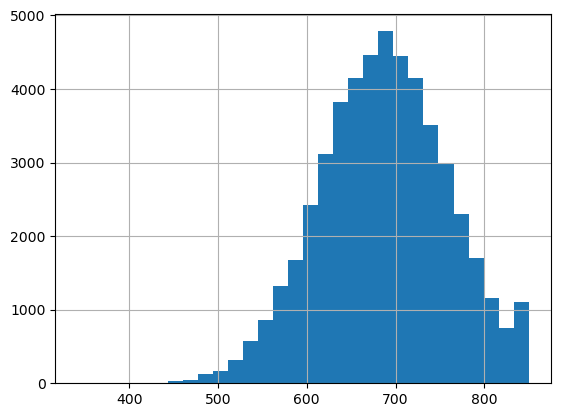

In [24]:
df["credit_score"].hist(bins=30)

In [25]:
df[df["annual_income"] <= 0]

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category


In [26]:
df["annual_income"].describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])

count     50000.000000
mean      71575.775340
std       44531.782805
min        8000.000000
1%        10953.031300
5%        19341.661500
25%       41901.082500
50%       61907.220000
75%       89987.405000
95%      154882.223000
99%      229931.179800
max      400000.000000
Name: annual_income, dtype: float64

In [27]:
df[df["loan_amount"] <= 0]

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category


In [28]:
df["loan_amount"].describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])

count     50000.000000
mean      18157.696609
std       15343.340488
min        1000.000000
1%         1796.002800
5%         3460.342500
25%        8105.402500
50%       13762.255000
75%       22970.882500
95%       47945.253000
99%       82064.562800
max      100000.000000
Name: loan_amount, dtype: float64

In [29]:
df[df["interest_rate"] <= 0]

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category


In [30]:
df["interest_rate"].describe()

count    50000.000000
mean        10.110549
std          2.865444
min          5.000000
25%          8.030000
50%         10.050000
75%         12.060000
max         23.590000
Name: interest_rate, dtype: float64

In [31]:
df["debt_to_income_ratio"].describe()

count    50000.000000
mean         0.229613
std          0.089787
min          0.020000
25%          0.168000
50%          0.227000
75%          0.289000
max          0.615000
Name: debt_to_income_ratio, dtype: float64

In [32]:
df[(df["debt_to_income_ratio"] < 0) |
   (df["debt_to_income_ratio"] > 1)]

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category


In [33]:
categorical_columns = [
    "gender",
    "employment_type",
    "home_ownership",
    "loan_purpose",
    "loan_status",
    "region",
    "risk_category"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- gender ---
gender
Male      29014
Female    20049
Other       937
Name: count, dtype: int64

--- employment_type ---
employment_type
Salaried         27957
Self-Employed    10963
Contract          7562
Unemployed        3518
Name: count, dtype: int64

--- home_ownership ---
home_ownership
Rent        19350
Mortgage    15843
Own         12220
Other        2087
Unknown       500
Name: count, dtype: int64

--- loan_purpose ---
loan_purpose
Debt Consolidation    13528
Auto                   8177
Home Improvement       6954
Personal               6373
Education              4501
Medical                4042
Business               3939
Other                  2486
Name: count, dtype: int64

--- loan_status ---
loan_status
Paid/Current    25669
Defaulted       18087
Delinquent       6244
Name: count, dtype: int64

--- region ---
region
West         10987
North        10944
South        10058
Central       8538
East          6422
Northeast     3051
Name: count, dtype: int64

--- risk_catego

In [34]:
df["default_flag"].value_counts()

default_flag
0    31913
1    18087
Name: count, dtype: int64

In [35]:
df["default_flag"].value_counts(normalize=True) * 100

default_flag
0    63.826
1    36.174
Name: proportion, dtype: float64

In [36]:
df["age_group"].value_counts()

age_group
30-39    17458
40-49    16613
21-29     8564
50-59     6367
60-70      998
Name: count, dtype: int64

In [37]:
df["income_group"].value_counts()

income_group
30K-60K      17653
60K-100K     16368
100K-200K     8898
<30K          6210
200K+          871
Name: count, dtype: int64

In [38]:
df["credit_score_band"].value_counts()

credit_score_band
Good         18010
Fair         16740
Very Good     8776
Poor          3455
Excellent     3019
Name: count, dtype: int64

In [39]:
df["dti_band"].value_counts()

dti_band
Moderate     26217
Low          19125
High          4545
Very High      113
Name: count, dtype: int64

In [40]:
df["risk_category"].value_counts()

risk_category
High Risk      49742
Medium Risk      258
Name: count, dtype: int64

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50000 entries, 0 to 49999
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   loan_id                  50000 non-null  int64         
 1   customer_id              50000 non-null  int64         
 2   age                      50000 non-null  int64         
 3   gender                   50000 non-null  object        
 4   annual_income            50000 non-null  float64       
 5   employment_type          50000 non-null  object        
 6   employment_length_years  50000 non-null  float64       
 7   credit_score             50000 non-null  int64         
 8   home_ownership           50000 non-null  object        
 9   existing_loans           50000 non-null  int64         
 10  delinquencies            50000 non-null  int64         
 11  previous_defaults        50000 non-null  int64         
 12  loan_purpose             50000 non-nu

In [42]:
df["default_flag"].value_counts(normalize=True) * 100

default_flag
0    63.826
1    36.174
Name: proportion, dtype: float64

In [43]:
df["credit_score"].describe()

count    50000.000000
mean       686.872320
std         71.706004
min        342.000000
25%        638.000000
50%        687.000000
75%        736.000000
max        850.000000
Name: credit_score, dtype: float64

In [44]:
df["debt_to_income_ratio"].describe()

count    50000.000000
mean         0.229613
std          0.089787
min          0.020000
25%          0.168000
50%          0.227000
75%          0.289000
max          0.615000
Name: debt_to_income_ratio, dtype: float64

In [45]:
df["loan_amount"].describe()

count     50000.000000
mean      18157.696609
std       15343.340488
min        1000.000000
25%        8105.402500
50%       13762.255000
75%       22970.882500
max      100000.000000
Name: loan_amount, dtype: float64

In [46]:
total_loans = df["loan_id"].nunique()

total_loan_amount = df["loan_amount"].sum()

avg_loan_amount = df["loan_amount"].mean()

defaulted_loans = df["default_flag"].sum()

default_rate = df["default_flag"].mean() * 100

avg_credit_score = df["credit_score"].mean()

avg_interest_rate = df["interest_rate"].mean()

avg_dti = df["debt_to_income_ratio"].mean()

print("Total Loans:", total_loans)
print("Total Loan Amount:", round(total_loan_amount, 2))
print("Average Loan Amount:", round(avg_loan_amount, 2))
print("Defaulted Loans:", defaulted_loans)
print("Default Rate:", round(default_rate, 2), "%")
print("Average Credit Score:", round(avg_credit_score, 2))
print("Average Interest Rate:", round(avg_interest_rate, 2), "%")
print("Average DTI:", round(avg_dti * 100, 2), "%")

Total Loans: 50000
Total Loan Amount: 907884830.43
Average Loan Amount: 18157.7
Defaulted Loans: 18087
Default Rate: 36.17 %
Average Credit Score: 686.87
Average Interest Rate: 10.11 %
Average DTI: 22.96 %


In [47]:
df.head()

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,issue_date,region,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category
0,500001,100001,44,Male,24653.44,Contract,6.8,731,Rent,1,...,2022-08-12,South,Paid/Current,0,40-49,<30K,Good,Moderate,74.1,High Risk
1,500002,100002,38,Male,49346.44,Salaried,10.6,720,Rent,4,...,2025-12-07,Central,Paid/Current,0,30-39,30K-60K,Good,Moderate,76.7,High Risk
2,500003,100003,45,Female,34513.60,Salaried,4.9,636,Own,1,...,2022-09-03,South,Paid/Current,0,40-49,30K-60K,Fair,Moderate,88.6,High Risk
3,500004,100004,54,Female,80078.43,Salaried,4.7,838,Rent,3,...,2023-09-01,North,Paid/Current,0,50-59,60K-100K,Excellent,High,75.4,High Risk
4,500005,100005,37,Male,65647.02,Contract,9.6,745,Mortgage,3,...,2023-09-10,West,Paid/Current,0,30-39,60K-100K,Very Good,Low,70.3,High Risk


In [48]:
default_summary = df.groupby("loan_status").agg(
    total_loans=("loan_id", "count"),
    total_loan_amount=("loan_amount", "sum"),
    avg_loan_amount=("loan_amount", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    avg_interest_rate=("interest_rate", "mean")
).round(2)

default_summary

,total_loans,total_loan_amount,avg_loan_amount,avg_credit_score,avg_dti,avg_interest_rate
loan_status,,,,,,
Defaulted,18087,3.397986e+08,18786.90,670.18,0.26,11.02
Delinquent,6244,1.138873e+08,18239.48,685.05,0.23,10.17
Paid/Current,25669,4.541989e+08,17694.45,699.08,0.21,9.45


In [49]:
credit_risk = df.groupby("credit_score_band", observed=True).agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

credit_risk["default_rate"] = (
    credit_risk["default_rate"] * 100
).round(2)

credit_risk


,credit_score_band,total_loans,defaults,default_rate
0,Excellent,3019,663,21.96
1,Fair,16740,7301,43.61
2,Good,18010,6001,33.32
3,Poor,3455,1789,51.78
4,Very Good,8776,2333,26.58


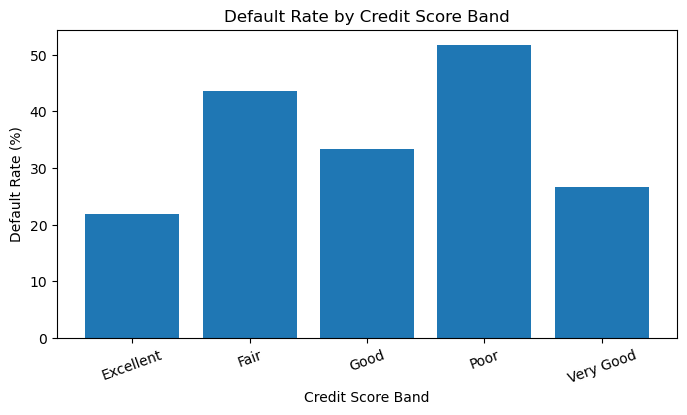

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.bar(
    credit_risk["credit_score_band"],
    credit_risk["default_rate"]
)

plt.xlabel("Credit Score Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Credit Score Band")
plt.xticks(rotation=20)

plt.show()

In [51]:
df.columns

Index(['loan_id', 'customer_id', 'age', 'gender', 'annual_income',
       'employment_type', 'employment_length_years', 'credit_score',
       'home_ownership', 'existing_loans', 'delinquencies',
       'previous_defaults', 'loan_purpose', 'loan_amount', 'loan_term_months',
       'interest_rate', 'debt_to_income_ratio', 'monthly_payment',
       'issue_date', 'region', 'loan_status', 'default_flag', 'age_group',
       'income_group', 'credit_score_band', 'dti_band', 'risk_score',
       'risk_category'],
      dtype='object')

In [52]:
default_analysis = df.groupby("default_flag").agg(
    total_loans=("loan_id", "count"),
    total_loan_amount=("loan_amount", "sum"),
    avg_loan_amount=("loan_amount", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    avg_interest_rate=("interest_rate", "mean"),
    avg_annual_income=("annual_income", "mean"),
    avg_delinquencies=("delinquencies", "mean"),
    avg_previous_defaults=("previous_defaults", "mean")
).reset_index()

default_analysis

,default_flag,total_loans,total_loan_amount,avg_loan_amount,avg_credit_score,avg_dti,avg_interest_rate,avg_annual_income,avg_delinquencies,avg_previous_defaults
0,0,31913,5.680862e+08,17801.090065,696.332999,0.214042,9.593881,71726.658159,0.332623,0.118948
1,1,18087,3.397986e+08,18786.899055,670.179742,0.257087,11.022168,71309.555216,0.575496,0.239841


In [53]:
credit_risk = df.groupby("credit_score_band", observed=True).agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

credit_risk["default_rate"] = (
    credit_risk["default_rate"] * 100
).round(2)

credit_risk

,credit_score_band,total_loans,defaults,default_rate
0,Excellent,3019,663,21.96
1,Fair,16740,7301,43.61
2,Good,18010,6001,33.32
3,Poor,3455,1789,51.78
4,Very Good,8776,2333,26.58


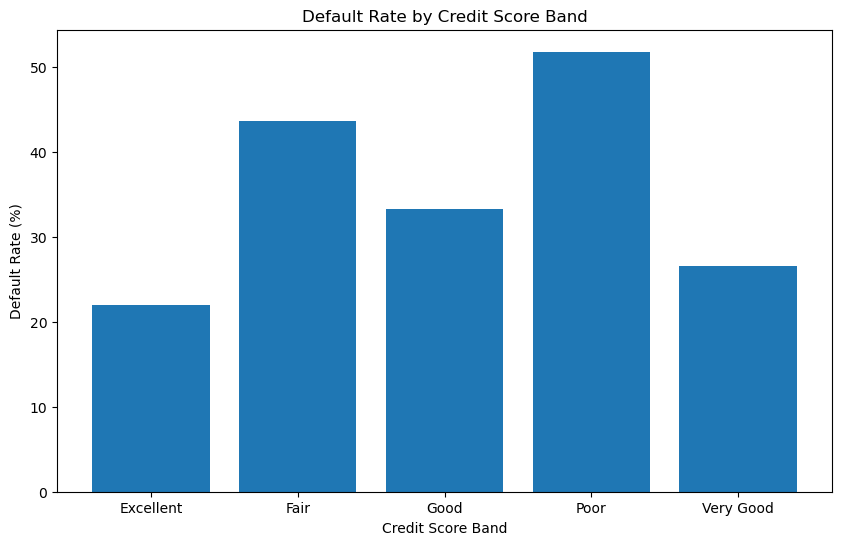

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    credit_risk["credit_score_band"],
    credit_risk["default_rate"]
)

plt.xlabel("Credit Score Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Credit Score Band")

plt.show()

In [55]:
dti_analysis = df.groupby("dti_band", observed=True).agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean"),
    avg_loan_amount=("loan_amount", "mean")
).reset_index()

dti_analysis["default_rate"] = (
    dti_analysis["default_rate"] * 100
).round(2)

dti_analysis

,dti_band,total_loans,defaults,default_rate,avg_loan_amount
0,High,4545,2663,58.59,23074.687386
1,Low,19125,4891,25.57,15916.043852
2,Moderate,26217,10436,39.81,18881.319418
3,Very High,113,97,85.84,31898.109912


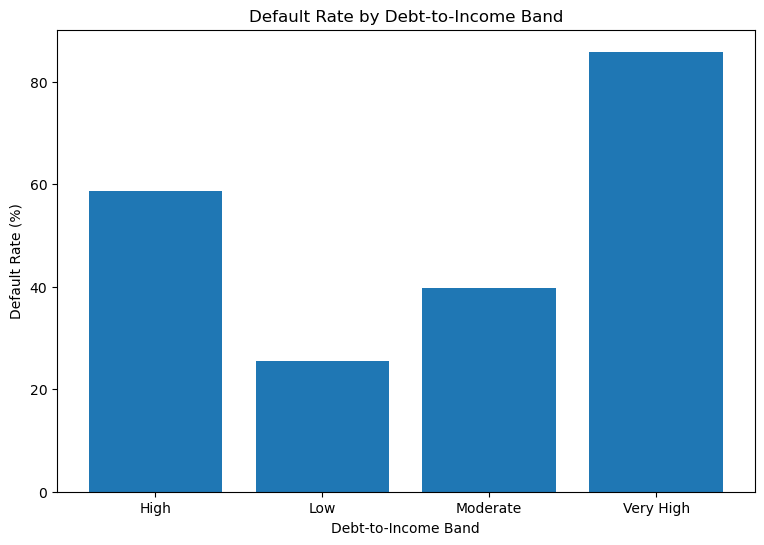

In [56]:
plt.figure(figsize=(9, 6))

plt.bar(
    dti_analysis["dti_band"],
    dti_analysis["default_rate"]
)

plt.xlabel("Debt-to-Income Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Debt-to-Income Band")

plt.show()

In [57]:
previous_default_analysis = df.groupby("previous_defaults").agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

previous_default_analysis["default_rate"] *= 100

previous_default_analysis

,previous_defaults,total_loans,defaults,default_rate
0,0,42232,13999,33.147850
1,1,7402,3838,51.850851
2,2,366,250,68.306011


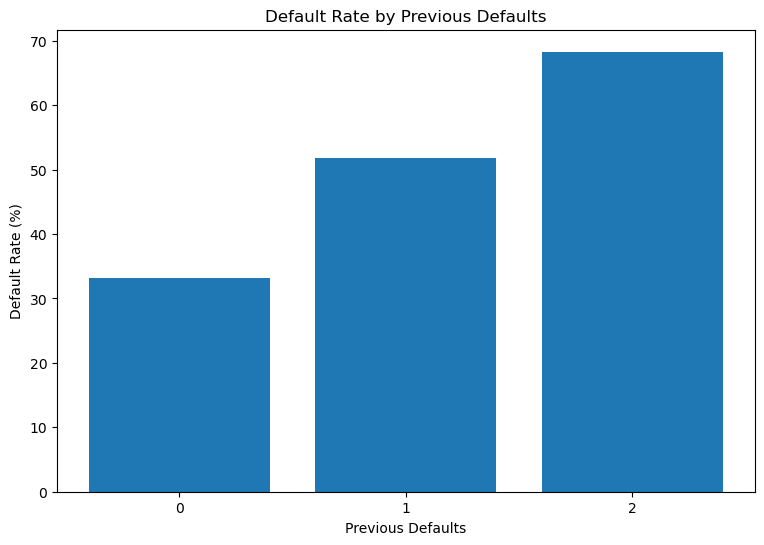

In [58]:
plt.figure(figsize=(9, 6))

plt.bar(
    previous_default_analysis["previous_defaults"].astype(str),
    previous_default_analysis["default_rate"]
)

plt.xlabel("Previous Defaults")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Previous Defaults")

plt.show()

In [59]:
purpose_analysis = df.groupby("loan_purpose").agg(
    total_loans=("loan_id", "count"),
    total_loan_amount=("loan_amount", "sum"),
    avg_loan_amount=("loan_amount", "mean"),
    avg_interest_rate=("interest_rate", "mean"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

purpose_analysis["default_rate"] *= 100

purpose_analysis = purpose_analysis.sort_values(
    "default_rate",
    ascending=False
)

purpose_analysis

,loan_purpose,total_loans,total_loan_amount,avg_loan_amount,avg_interest_rate,defaults,default_rate
1,Business,3939,1.113853e+08,28277.551300,10.219551,1650,41.888804
5,Medical,4042,4.558717e+07,11278.368570,9.973850,1526,37.753587
4,Home Improvement,6954,1.624391e+08,23359.083208,10.208801,2556,36.755824
0,Auto,8177,1.650178e+08,20180.721032,10.128858,2920,35.709918
2,Debt Consolidation,13528,2.524333e+08,18660.061895,10.142448,4814,35.585452
6,Other,2486,3.118283e+07,12543.373222,9.972204,876,35.237329
3,Education,4501,6.110335e+07,13575.505108,10.077061,1566,34.792268
7,Personal,6373,7.873608e+07,12354.633289,10.009085,2179,34.191119


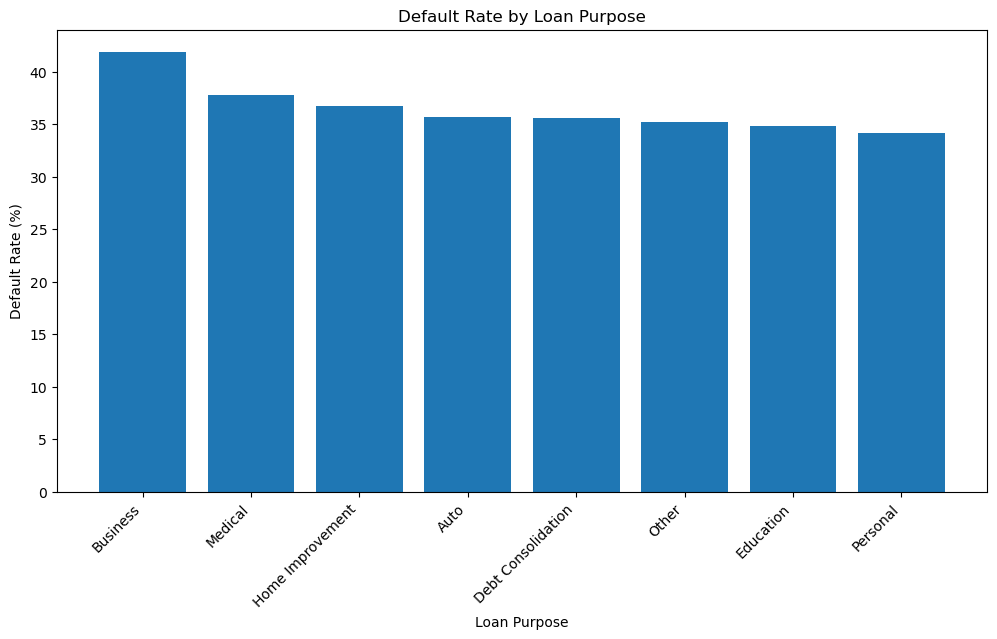

In [60]:
plt.figure(figsize=(12, 6))

plt.bar(
    purpose_analysis["loan_purpose"],
    purpose_analysis["default_rate"]
)

plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Purpose")
plt.xticks(rotation=45, ha="right")

plt.show()

In [61]:
risk_matrix = pd.pivot_table(
    df,
    values="default_flag",
    index="credit_score_band",
    columns="dti_band",
    aggfunc="mean"
) * 100

risk_matrix.round(2)

dti_band,High,Low,Moderate,Very High
credit_score_band,,,,
Excellent,51.38,13.70,23.40,60.00
Fair,65.61,32.43,47.54,83.72
Good,55.03,22.93,36.90,85.37
Poor,72.00,41.00,56.50,100.00
Very Good,49.69,16.16,29.93,94.74


In [62]:
dti_analysis = df.groupby("dti_band", observed=True).agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean"),
    avg_loan_amount=("loan_amount", "mean")
).reset_index()

dti_analysis["default_rate"] = (
    dti_analysis["default_rate"] * 100
).round(2)

dti_analysis

,dti_band,total_loans,defaults,default_rate,avg_loan_amount
0,High,4545,2663,58.59,23074.687386
1,Low,19125,4891,25.57,15916.043852
2,Moderate,26217,10436,39.81,18881.319418
3,Very High,113,97,85.84,31898.109912


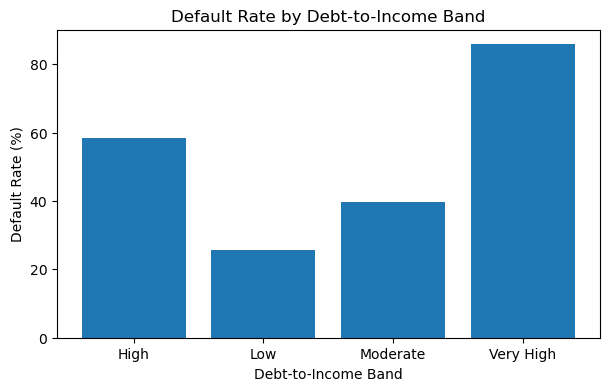

In [63]:
plt.figure(figsize=(7, 4))

plt.bar(
    dti_analysis["dti_band"],
    dti_analysis["default_rate"]
)

plt.xlabel("Debt-to-Income Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Debt-to-Income Band")

plt.show()

In [64]:
previous_default_analysis = df.groupby("previous_defaults").agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean"),
    avg_loan_amount=("loan_amount", "mean"),
    avg_credit_score=("credit_score", "mean")
).reset_index()

previous_default_analysis["default_rate"] = (
    previous_default_analysis["default_rate"] * 100
).round(2)

previous_default_analysis

,previous_defaults,total_loans,defaults,default_rate,avg_loan_amount,avg_credit_score
0,0,42232,13999,33.15,18159.504591,687.191016
1,1,7402,3838,51.85,18080.075857,685.104161
2,2,366,250,68.31,19518.882678,685.857923


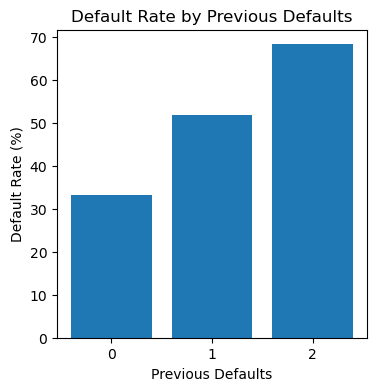

In [65]:
plt.figure(figsize=(4, 4))

plt.bar(
    previous_default_analysis["previous_defaults"].astype(str),
    previous_default_analysis["default_rate"]
)

plt.xlabel("Previous Defaults")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Previous Defaults")

plt.show()

In [66]:
delinquency_analysis = df.groupby("delinquencies").agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean")
).reset_index()

delinquency_analysis["default_rate"] = (
    delinquency_analysis["default_rate"] * 100
).round(2)

delinquency_analysis

,delinquencies,total_loans,defaults,default_rate,avg_credit_score,avg_dti
0,0,32915,10088,30.65,686.683640,0.222605
1,1,13663,5948,43.53,687.352046,0.239035
2,2,2954,1729,58.53,686.408937,0.257022
3,3,420,286,68.10,689.045238,0.272876
4,4,47,35,74.47,689.829787,0.284021
5,5,1,1,100.00,660.000000,0.495000


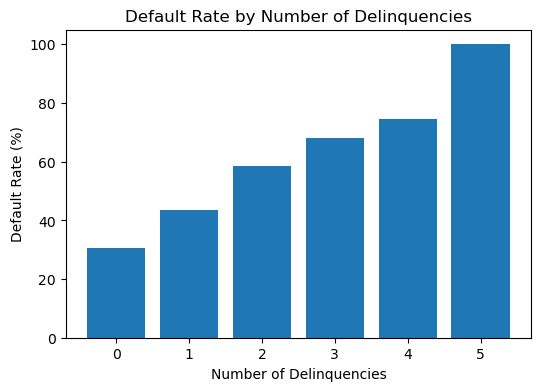

In [67]:
plt.figure(figsize=(6, 4))

plt.bar(
    delinquency_analysis["delinquencies"].astype(str),
    delinquency_analysis["default_rate"]
)

plt.xlabel("Number of Delinquencies")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Number of Delinquencies")

plt.show()

In [68]:
purpose_analysis = df.groupby("loan_purpose").agg(
    total_loans=("loan_id", "count"),
    total_loan_amount=("loan_amount", "sum"),
    avg_loan_amount=("loan_amount", "mean"),
    avg_interest_rate=("interest_rate", "mean"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

purpose_analysis["default_rate"] = (
    purpose_analysis["default_rate"] * 100
).round(2)

purpose_analysis["total_loan_amount_millions"] = (
    purpose_analysis["total_loan_amount"] / 1_000_000
).round(2)

purpose_analysis = purpose_analysis.sort_values(
    "default_rate",
    ascending=False
)

purpose_analysis

,loan_purpose,total_loans,total_loan_amount,avg_loan_amount,avg_interest_rate,defaults,default_rate,total_loan_amount_millions
1,Business,3939,1.113853e+08,28277.551300,10.219551,1650,41.89,111.39
5,Medical,4042,4.558717e+07,11278.368570,9.973850,1526,37.75,45.59
4,Home Improvement,6954,1.624391e+08,23359.083208,10.208801,2556,36.76,162.44
0,Auto,8177,1.650178e+08,20180.721032,10.128858,2920,35.71,165.02
2,Debt Consolidation,13528,2.524333e+08,18660.061895,10.142448,4814,35.59,252.43
6,Other,2486,3.118283e+07,12543.373222,9.972204,876,35.24,31.18
3,Education,4501,6.110335e+07,13575.505108,10.077061,1566,34.79,61.10
7,Personal,6373,7.873608e+07,12354.633289,10.009085,2179,34.19,78.74


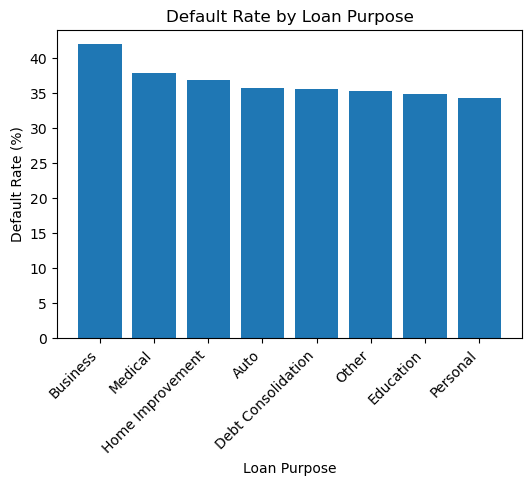

In [69]:
plt.figure(figsize=(6, 4))

plt.bar(
    purpose_analysis["loan_purpose"],
    purpose_analysis["default_rate"]
)

plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Purpose")
plt.xticks(rotation=45, ha="right")

plt.show()

In [70]:
employment_analysis = df.groupby("employment_type").agg(
    total_loans=("loan_id", "count"),
    total_loan_amount=("loan_amount", "sum"),
    avg_income=("annual_income", "mean"),
    avg_loan_amount=("loan_amount", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

employment_analysis["default_rate"] = (
    employment_analysis["default_rate"] * 100
).round(2)

employment_analysis["total_loan_amount_millions"] = (
    employment_analysis["total_loan_amount"] / 1_000_000
).round(2)

employment_analysis["avg_dti"] = (
    employment_analysis["avg_dti"] * 100
).round(2)

employment_analysis

,employment_type,total_loans,total_loan_amount,avg_income,avg_loan_amount,avg_credit_score,avg_dti,defaults,default_rate,total_loan_amount_millions
0,Contract,7562,1.159649e+08,60771.468967,15335.213348,688.768844,22.86,2646,34.99,115.96
1,Salaried,27957,5.202696e+08,72916.692367,18609.637989,689.883142,22.97,9697,34.69,520.27
2,Self-Employed,10963,2.536103e+08,92168.315925,23133.295418,688.808355,22.95,3868,35.28,253.61
3,Unemployed,3518,1.803998e+07,19972.058752,5127.907951,652.835986,23.19,1876,53.33,18.04


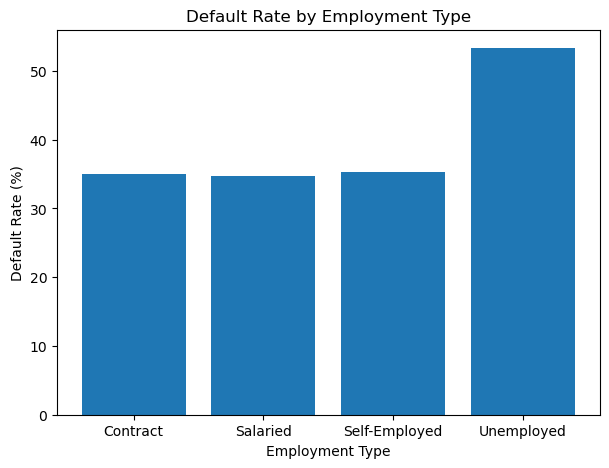

In [71]:
plt.figure(figsize=(7, 5))

plt.bar(
    employment_analysis["employment_type"],
    employment_analysis["default_rate"]
)

plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Employment Type")

plt.show()

In [72]:
employment_analysis = employment_analysis.drop(
    columns=["total_loan_amount"]
)

employment_analysis

,employment_type,total_loans,avg_income,avg_loan_amount,avg_credit_score,avg_dti,defaults,default_rate,total_loan_amount_millions
0,Contract,7562,60771.468967,15335.213348,688.768844,22.86,2646,34.99,115.96
1,Salaried,27957,72916.692367,18609.637989,689.883142,22.97,9697,34.69,520.27
2,Self-Employed,10963,92168.315925,23133.295418,688.808355,22.95,3868,35.28,253.61
3,Unemployed,3518,19972.058752,5127.907951,652.835986,23.19,1876,53.33,18.04


In [73]:
income_analysis = df.groupby("income_group", observed=True).agg(
    total_loans=("loan_id", "count"),
    total_loan_amount=("loan_amount", "sum"),
    avg_income=("annual_income", "mean"),
    avg_loan_amount=("loan_amount", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

income_analysis["default_rate"] = (
    income_analysis["default_rate"] * 100
).round(2)

income_analysis["avg_dti"] = (
    income_analysis["avg_dti"] * 100
).round(2)

income_analysis["total_loan_amount_millions"] = (
    income_analysis["total_loan_amount"] / 1_000_000
).round(2)

income_analysis

,income_group,total_loans,total_loan_amount,avg_income,avg_loan_amount,avg_credit_score,avg_dti,defaults,default_rate,total_loan_amount_millions
0,100K-200K,8898,2.953555e+08,130511.445980,33193.465053,689.142841,22.97,3246,36.48,295.36
1,200K+,871,5.249194e+07,252666.308507,60266.286303,685.668197,23.26,347,39.84,52.49
2,30K-60K,17653,2.055629e+08,45638.471037,11644.641715,688.692743,22.95,6075,34.41,205.56
3,60K-100K,16368,3.212989e+08,77187.535697,19629.700898,689.247495,22.93,5786,35.35,321.30
4,<30K,6210,3.317564e+07,20670.539850,5342.292839,672.352657,23.03,2633,42.40,33.18


In [74]:
income_analysis = income_analysis.drop( columns=["total_loan_amount"])

In [75]:
income_analysis

,income_group,total_loans,avg_income,avg_loan_amount,avg_credit_score,avg_dti,defaults,default_rate,total_loan_amount_millions
0,100K-200K,8898,130511.445980,33193.465053,689.142841,22.97,3246,36.48,295.36
1,200K+,871,252666.308507,60266.286303,685.668197,23.26,347,39.84,52.49
2,30K-60K,17653,45638.471037,11644.641715,688.692743,22.95,6075,34.41,205.56
3,60K-100K,16368,77187.535697,19629.700898,689.247495,22.93,5786,35.35,321.30
4,<30K,6210,20670.539850,5342.292839,672.352657,23.03,2633,42.40,33.18


## Loan amount analysis

In [77]:
df["loan_amount_band"] = pd.cut(
    df["loan_amount"],
    bins=[0, 5000, 10000, 25000, 50000, 100000],
    labels=[
        "<5K",
        "5K-10K",
        "10K-25K",
        "25K-50K",
        "50K+"
    ],
    include_lowest=True
)

In [78]:
loan_amount_analysis = df.groupby(
    "loan_amount_band",
    observed=True
).agg(
    total_loans=("loan_id", "count"),
    total_exposure=("loan_amount", "sum"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

loan_amount_analysis["default_rate"] = (
    loan_amount_analysis["default_rate"] * 100
).round(2)

loan_amount_analysis["avg_dti"] = (
    loan_amount_analysis["avg_dti"] * 100
).round(2)

loan_amount_analysis["total_exposure_millions"] = (
    loan_amount_analysis["total_exposure"] / 1_000_000
).round(2)

loan_amount_analysis

,loan_amount_band,total_loans,total_exposure,avg_credit_score,avg_dti,defaults,default_rate,total_exposure_millions
0,<5K,5343,1.825723e+07,677.119970,21.29,2151,40.26,18.26
1,5K-10K,11685,8.804384e+07,686.312794,21.80,4101,35.10,88.04
2,10K-25K,22152,3.574171e+08,688.461448,22.92,7631,34.45,357.42
3,25K-50K,8574,2.899155e+08,689.342081,24.65,3214,37.49,289.92
4,50K+,2246,1.542511e+08,687.881567,26.94,990,44.08,154.25


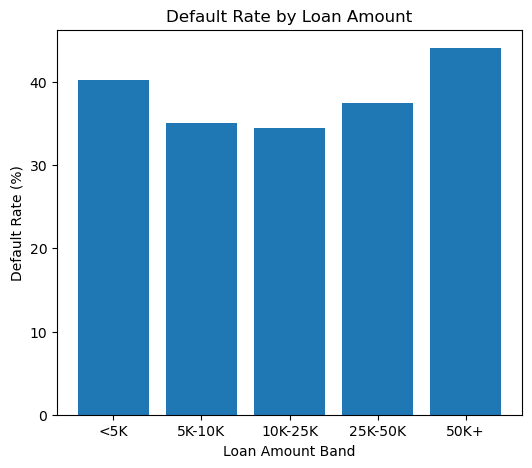

In [79]:
plt.figure(figsize=(6, 5))

plt.bar(
    loan_amount_analysis["loan_amount_band"],
    loan_amount_analysis["default_rate"]
)

plt.xlabel("Loan Amount Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Amount")

plt.show()

In [80]:
df["loan_amount_band"] = pd.cut(
    df["loan_amount"],
    bins=[0, 5000, 10000, 25000, 50000, 100000],
    labels=["<5K", "5K-10K", "10K-25K", "25K-50K", "50K+"],
    include_lowest=True
)

In [81]:
loan_amount_analysis = df.groupby(
    "loan_amount_band",
    observed=True
).agg(
    total_loans=("loan_id", "count"),
    total_exposure=("loan_amount", "sum"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
).reset_index()

loan_amount_analysis["default_rate"] = (
    loan_amount_analysis["default_rate"] * 100
).round(2)

loan_amount_analysis["avg_dti"] = (
    loan_amount_analysis["avg_dti"] * 100
).round(2)

loan_amount_analysis["total_exposure_millions"] = (
    loan_amount_analysis["total_exposure"] / 1_000_000
).round(2)

loan_amount_analysis

,loan_amount_band,total_loans,total_exposure,avg_credit_score,avg_dti,defaults,default_rate,total_exposure_millions
0,<5K,5343,1.825723e+07,677.119970,21.29,2151,40.26,18.26
1,5K-10K,11685,8.804384e+07,686.312794,21.80,4101,35.10,88.04
2,10K-25K,22152,3.574171e+08,688.461448,22.92,7631,34.45,357.42
3,25K-50K,8574,2.899155e+08,689.342081,24.65,3214,37.49,289.92
4,50K+,2246,1.542511e+08,687.881567,26.94,990,44.08,154.25


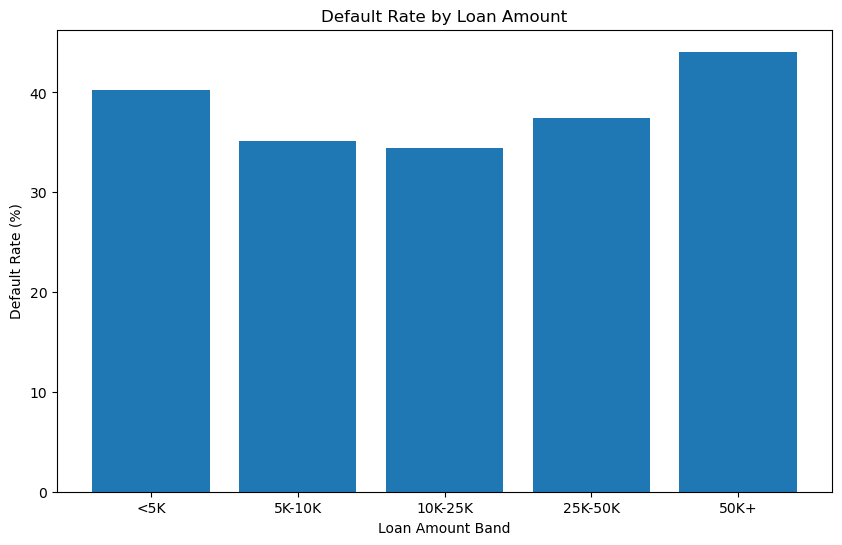

In [82]:
plt.figure(figsize=(10, 6))

plt.bar(
    loan_amount_analysis["loan_amount_band"],
    loan_amount_analysis["default_rate"]
)

plt.xlabel("Loan Amount Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Amount")

plt.show()

In [83]:
df["loan_to_income_ratio"] = (
    df["loan_amount"] / df["annual_income"]
)

In [84]:
df.head()

,loan_id,customer_id,age,gender,annual_income,employment_type,employment_length_years,credit_score,home_ownership,existing_loans,...,loan_status,default_flag,age_group,income_group,credit_score_band,dti_band,risk_score,risk_category,loan_amount_band,loan_to_income_ratio
0,500001,100001,44,Male,24653.44,Contract,6.8,731,Rent,1,...,Paid/Current,0,40-49,<30K,Good,Moderate,74.1,High Risk,5K-10K,0.295468
1,500002,100002,38,Male,49346.44,Salaried,10.6,720,Rent,4,...,Paid/Current,0,30-39,30K-60K,Good,Moderate,76.7,High Risk,10K-25K,0.328130
2,500003,100003,45,Female,34513.60,Salaried,4.9,636,Own,1,...,Paid/Current,0,40-49,30K-60K,Fair,Moderate,88.6,High Risk,5K-10K,0.257261
3,500004,100004,54,Female,80078.43,Salaried,4.7,838,Rent,3,...,Paid/Current,0,50-59,60K-100K,Excellent,High,75.4,High Risk,25K-50K,0.470332
4,500005,100005,37,Male,65647.02,Contract,9.6,745,Mortgage,3,...,Paid/Current,0,30-39,60K-100K,Very Good,Low,70.3,High Risk,10K-25K,0.278457


In [85]:
risk_matrix = pd.pivot_table(
    df,
    values="default_flag",
    index="credit_score_band",
    columns="dti_band",
    aggfunc="mean"
) * 100

risk_matrix.round(2)

dti_band,High,Low,Moderate,Very High
credit_score_band,,,,
Excellent,51.38,13.70,23.40,60.00
Fair,65.61,32.43,47.54,83.72
Good,55.03,22.93,36.90,85.37
Poor,72.00,41.00,56.50,100.00
Very Good,49.69,16.16,29.93,94.74


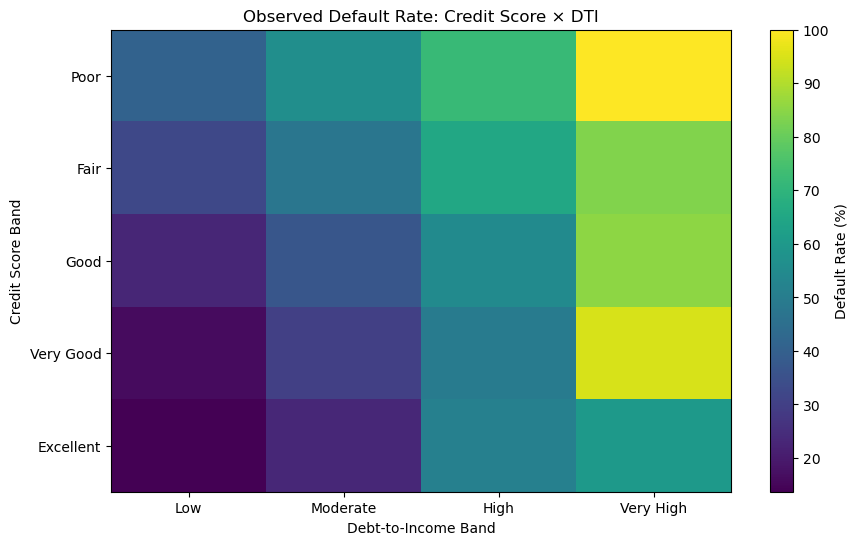

In [86]:
import matplotlib.pyplot as plt

risk_matrix_plot = risk_matrix.reindex(
    index=["Poor", "Fair", "Good", "Very Good", "Excellent"],
    columns=["Low", "Moderate", "High", "Very High"]
)

plt.figure(figsize=(10, 6))

plt.imshow(
    risk_matrix_plot,
    aspect="auto"
)

plt.xticks(
    range(len(risk_matrix_plot.columns)),
    risk_matrix_plot.columns
)

plt.yticks(
    range(len(risk_matrix_plot.index)),
    risk_matrix_plot.index
)

plt.xlabel("Debt-to-Income Band")
plt.ylabel("Credit Score Band")
plt.title("Observed Default Rate: Credit Score × DTI")

plt.colorbar(label="Default Rate (%)")

plt.show()

In [87]:
df["loan_to_income_ratio"].describe()

count    50000.000000
mean         0.254774
std          0.134305
min          0.036878
25%          0.159855
50%          0.225232
75%          0.316526
max          1.287119
Name: loan_to_income_ratio, dtype: float64

In [88]:
df[df["loan_to_income_ratio"] > 2].shape

(0, 30)

In [89]:
import numpy as np

df["loan_to_income_band"] = pd.cut(
    df["loan_to_income_ratio"],
    bins=[0, 0.10, 0.20, 0.30, 0.50, 1.00, np.inf],
    labels=[
        "<10%",
        "10%-20%",
        "20%-30%",
        "30%-50%",
        "50%-100%",
        "100%+"
    ],
    include_lowest=True
)

In [90]:
lti_analysis = df.groupby(
    "loan_to_income_band",
    observed=True
).agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    avg_loan_amount=("loan_amount", "mean")
).reset_index()

lti_analysis["default_rate"] = (
    lti_analysis["default_rate"] * 100
).round(2)

lti_analysis["avg_dti"] = (
    lti_analysis["avg_dti"] * 100
).round(2)

lti_analysis

,loan_to_income_band,total_loans,defaults,default_rate,avg_credit_score,avg_dti,avg_loan_amount
0,<10%,2667,879,32.96,687.479190,19.96,5998.069779
1,10%-20%,17685,6135,34.69,686.800283,21.20,10958.731976
2,20%-30%,15392,5554,36.08,685.821596,22.83,17724.667519
3,30%-50%,11516,4327,37.57,688.616968,25.03,26784.728986
4,50%-100%,2703,1174,43.43,685.260081,29.24,42388.507543
5,100%+,37,18,48.65,689.432432,36.77,60422.864595


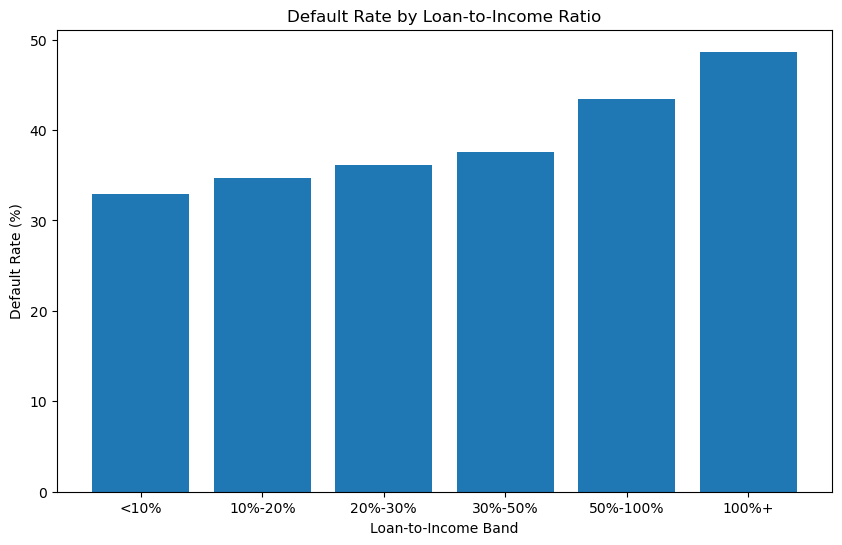

In [91]:
plt.figure(figsize=(10, 6))

plt.bar(
    lti_analysis["loan_to_income_band"],
    lti_analysis["default_rate"]
)

plt.xlabel("Loan-to-Income Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan-to-Income Ratio")

plt.show()

In [92]:
credit_risk_points = {
    "Excellent": 0,
    "Very Good": 1,
    "Good": 2,
    "Fair": 3,
    "Poor": 4
}

In [93]:
dti_risk_points = {
    "Low": 0,
    "Moderate": 1,
    "High": 2,
    "Very High": 3
}

In [94]:
df["credit_risk_points"] = df["credit_score_band"].map(
    credit_risk_points
)

df["dti_risk_points"] = df["dti_band"].map(
    dti_risk_points
)

In [95]:
df["previous_default_points"] = df["previous_defaults"].clip(
    upper=3
)

In [96]:
df["risk_points"] = (
    df["credit_risk_points"]
    + df["dti_risk_points"]
    + df["previous_default_points"]
)

In [97]:
df["risk_points"].describe()

count    50000.000000
mean         3.052320
std          1.250126
min          0.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          8.000000
Name: risk_points, dtype: float64

In [98]:
df["risk_points"].value_counts().sort_index()

risk_points
0     1027
1     4362
2    10650
3    15665
4    12585
5     4735
6      893
7       78
8        5
Name: count, dtype: int64

In [99]:
df["risk_category_analysis"] = pd.cut(
    df["risk_points"],
    bins=[-1, 2, 5, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

In [100]:
risk_segment_analysis = df.groupby(
    "risk_category_analysis",
    observed=True
).agg(
    total_loans=("loan_id", "count"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_dti=("debt_to_income_ratio", "mean"),
    avg_loan_amount=("loan_amount", "mean")
).reset_index()

risk_segment_analysis["default_rate"] = (
    risk_segment_analysis["default_rate"] * 100
).round(2)

risk_segment_analysis["avg_dti"] = (
    risk_segment_analysis["avg_dti"] * 100
).round(2)

risk_segment_analysis

,risk_category_analysis,total_loans,defaults,default_rate,avg_credit_score,avg_dti,avg_loan_amount
0,Low Risk,16039,3390,21.14,753.637446,18.60,17297.514150
1,Medium Risk,32985,13957,42.31,657.575322,24.74,18506.378322
2,High Risk,976,740,75.82,579.818648,34.69,20509.336107


In [101]:
risk_segment_analysis["share_of_total_defaults"] = (
    risk_segment_analysis["defaults"]
    / df["default_flag"].sum()
    * 100
).round(2)

risk_segment_analysis

,risk_category_analysis,total_loans,defaults,default_rate,avg_credit_score,avg_dti,avg_loan_amount,share_of_total_defaults
0,Low Risk,16039,3390,21.14,753.637446,18.60,17297.514150,18.74
1,Medium Risk,32985,13957,42.31,657.575322,24.74,18506.378322,77.17
2,High Risk,976,740,75.82,579.818648,34.69,20509.336107,4.09


In [102]:
risk_segment_analysis["total_exposure"] = (
    df.groupby("risk_category_analysis", observed=True)["loan_amount"]
    .sum()
    .values
)

risk_segment_analysis["exposure_millions"] = (
    risk_segment_analysis["total_exposure"] / 1_000_000
).round(2)

risk_segment_analysis

,risk_category_analysis,total_loans,defaults,default_rate,avg_credit_score,avg_dti,avg_loan_amount,share_of_total_defaults,total_exposure,exposure_millions
0,Low Risk,16039,3390,21.14,753.637446,18.60,17297.514150,18.74,2.774348e+08,277.43
1,Medium Risk,32985,13957,42.31,657.575322,24.74,18506.378322,77.17,6.104329e+08,610.43
2,High Risk,976,740,75.82,579.818648,34.69,20509.336107,4.09,2.001711e+07,20.02
